# 2 · Dynamic programming: optimal trade execution and a cost-aware allocation policy
Two finance problems solved exactly with dynamic programming.

1. **Optimal execution.** Sell a large block over a fixed number of periods. Selling fast costs price impact; selling slowly leaves the position exposed to price moves. Backward induction on an inventory grid gives the optimal schedule for each risk aversion, and is checked against the closed-form Almgren-Chriss (2000) solution.
2. **Allocation with transaction costs.** An investor sets the equity weight each month. Market regimes follow a Markov chain estimated from S&P 500 data, and changing the weight costs money. Value iteration and policy iteration find the optimal policy and confirm each other.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = ROOT / "images"; DATA = ROOT / "data"
from rlfin import mdp

## 1. Optimal execution
Sell **X = 200 blocks** over **N = 20 periods**. Temporary impact costs η·n² per period for selling n blocks (η = 0.05); each block held exposes the trader to price variance σ² = 1 per period, penalised by risk aversion λ (mean-variance objective). The expected cost of a schedule is Σ η nₖ² and the variance of its cost is σ² Σ xₖ², where xₖ is the inventory still held.

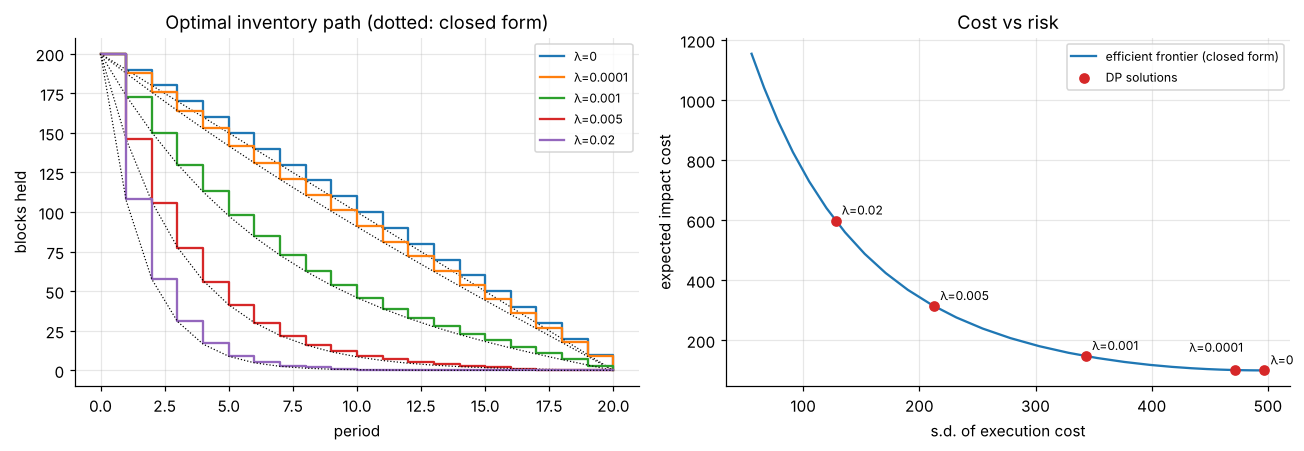

,λ,expected impact cost,s.d. of cost,max |DP − closed form| (blocks),share sold in first 5 periods %
0,0,100.0,496.991,0.000,25.0
1,0.0001,101.2,471.677,0.725,29.0
2,0.001,147.7,343.431,0.831,51.0
3,0.005,314.1,212.760,0.803,79.5
4,0.02,598.8,128.055,0.665,95.5


In [2]:
X, N, eta, sigma = 200, 20, 0.05, 1.0
lams = [0.0, 1e-4, 1e-3, 5e-3, 2e-2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
rows = []
for lam in lams:
    _, pol = mdp.solve_execution(X, N, eta, sigma, lam)
    path = mdp.schedule(pol, X); exact = mdp.almgren_chriss(X, N, eta, sigma, lam)
    n = -np.diff(path); E = eta * (n ** 2).sum(); SD = sigma * np.sqrt((path[1:] ** 2).sum())
    rows.append({"λ": f"{lam:g}", "expected impact cost": E, "s.d. of cost": SD, "max |DP − closed form| (blocks)": np.abs(path - exact).max(),
                 "share sold in first 5 periods %": 100 * (X - path[5]) / X})
    ax[0].step(range(N + 1), path, where="post", label=f"λ={lam:g}"); ax[0].plot(exact, "k:", lw=0.8)
ax[0].set_title("Optimal inventory path (dotted: closed form)"); ax[0].set_xlabel("period"); ax[0].set_ylabel("blocks held"); ax[0].legend(fontsize=8)
lam_grid = np.logspace(-6, -1, 40); fr = []
for lam in lam_grid:
    p = mdp.almgren_chriss(X, N, eta, sigma, lam); n = -np.diff(p); fr.append((eta * (n ** 2).sum(), sigma * np.sqrt((p[1:] ** 2).sum())))
fr = np.array(fr); ax[1].plot(fr[:, 1], fr[:, 0], "-", label="efficient frontier (closed form)")
t = pd.DataFrame(rows); ax[1].scatter(t["s.d. of cost"], t["expected impact cost"], c="C3", zorder=3, label="DP solutions")
for j, r in t.iterrows(): ax[1].annotate(f"λ={r['λ']}", (r["s.d. of cost"], r["expected impact cost"]), fontsize=8, xytext=(-30, 12) if j == 1 else (4, 4), textcoords="offset points")
ax[1].set_xlabel("s.d. of execution cost"); ax[1].set_ylabel("expected impact cost"); ax[1].set_title("Cost vs risk"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "optimal_execution.png", bbox_inches="tight"); plt.show()
t.round(3)

## 2. Allocation with regimes and transaction costs
**Regime.** Each month the S&P 500 (SPY, total return) is in an *up-trend* if it closes above its 10-month average and a *down-trend* otherwise. The regime is observable at month end, so a policy can act on it. Transition probabilities and the mean and variance of next-month returns in each regime are estimated from 2000-2026.

**Decision.** Equity weight w ∈ {0, 0.25, 0.5, 0.75, 1}, the rest in cash. Reward = mean-variance utility of next month's return, w·μ − ½·A·w²·σ² (A = 4), minus a cost of c·|Δw|. The state is (regime, current weight).

In [3]:
px = pd.read_csv(DATA / "etfs_daily.csv", index_col=0, parse_dates=True)["SPY"]
spy_m = pd.read_csv(DATA / "sector_etfs.csv", index_col=0, parse_dates=True)["SPY"].resample("ME").last()
ret = spy_m.pct_change(); up = (spy_m > spy_m.rolling(10).mean()).astype(int)
d = pd.DataFrame({"regime": up, "next": ret.shift(-1)}).dropna().iloc[10:]
reg = d["regime"].to_numpy()
Ptr = np.zeros((2, 2))
for a, b in zip(reg[:-1], reg[1:]): Ptr[a, b] += 1
Ptr /= Ptr.sum(1, keepdims=True)
mu = d.groupby("regime")["next"].mean().to_numpy(); sd = d.groupby("regime")["next"].std().to_numpy()
print(f"{len(d)} months, {d.index[0]:%b %Y} to {d.index[-1]:%b %Y}")
pd.DataFrame({"months": d["regime"].value_counts().sort_index().to_numpy(), "next-month mean %": 100 * mu, "next-month s.d. %": 100 * sd,
              "P(stay in regime)": np.diag(Ptr)}, index=["down-trend", "up-trend"]).round(3)

323 months, Nov 1999 to Sep 2026


,months,next-month mean %,next-month s.d. %,P(stay in regime)
down-trend,80,0.400,6.537,0.762
up-trend,243,0.889,3.365,0.921


In [4]:
W = np.array([0, 0.25, 0.5, 0.75, 1.0]); A_risk = 4.0; gamma = 0.99
def build(cost):
    S = 2 * len(W); nA = len(W)
    P = np.zeros((nA, S, S)); Rw = np.zeros((S, nA))
    for g in range(2):
        for i in range(len(W)):
            s = g * len(W) + i
            for a in range(nA):
                Rw[s, a] = W[a] * mu[g] - 0.5 * A_risk * W[a] ** 2 * sd[g] ** 2 - cost * abs(W[a] - W[i])
                for g2 in range(2): P[a, s, g2 * len(W) + a] = Ptr[g, g2]
    return P, Rw
rows = {}
for cost in [0.0, 0.002, 0.01, 0.03]:
    P, Rw = build(cost)
    V1, pi1 = mdp.value_iteration(P, Rw, gamma); V2, pi2 = mdp.policy_iteration(P, Rw, gamma)
    assert (pi1 == pi2).all() and np.allclose(V1, V2, atol=1e-6)
    tab = pd.DataFrame(W[pi1].reshape(2, len(W)), index=["down-trend", "up-trend"], columns=[f"from w={x:g}" for x in W])
    rows[f"cost {cost:.1%}"] = tab
pd.concat(rows, names=["cost per unit of turnover", "regime"])

from w=0  from w=0.25  from w=0.5  \
cost per unit of turnover regime                                          
cost 0.0%                 down-trend      0.25         0.25        0.25   
                          up-trend        1.00         1.00        1.00   
cost 0.2%                 down-trend      0.25         0.25        0.25   
                          up-trend        1.00         1.00        1.00   
cost 1.0%                 down-trend      0.25         0.25        0.50   
                          up-trend        1.00         1.00        1.00   
cost 3.0%                 down-trend      0.25         0.25        0.50   
                          up-trend        1.00         1.00        1.00   

                                      from w=0.75  from w=1  
cost per unit of turnover regime                             
cost 0.0%                 down-trend         0.25      0.25  
                          up-trend           1.00      1.00  
cost 0.2%                 down-trend         0.25      0.25  
                          up-trend           1.00      1.00  
cost 1.0%                 down-trend         0.50      0.50  
                          up-trend           1.00      1.00  
cost 3.0%                 down-trend         0.75      1.00  
                          up-trend           1.00      1.00

In [5]:
# Backtest: apply each policy month by month (estimated in-sample, so this illustrates behaviour rather than proves skill)
out = {}
for cost in [0.0, 0.01]:
    P, Rw = build(cost); _, pi = mdp.value_iteration(P, Rw, gamma)
    i = len(W) - 1; ws = []
    for g in reg:
        a = pi[g * len(W) + i]; ws.append(W[a]); i = a
    ws = np.array(ws); trade = np.abs(np.diff(np.r_[1.0, ws]))
    r = ws * d["next"].to_numpy() - 0.002 * trade
    out[f"DP policy (planned with cost {cost:.0%})"] = (r, trade.sum() / (len(ws) / 12))
out["100% SPY"] = (d["next"].to_numpy(), 0.0)
def s(r):
    w = np.cumprod(1 + r); vol = r.std() * np.sqrt(12)
    return {"ann. return %": 100 * (w[-1] ** (12 / len(r)) - 1), "ann. vol %": 100 * vol, "Sharpe (rf=0)": r.mean() * 12 / vol, "max drawdown %": 100 * (w / np.maximum.accumulate(w) - 1).min()}
pd.DataFrame({n: {**s(r), "turnover per year": to} for n, (r, to) in out.items()}).T.round(2)

,ann. return %,ann. vol %,Sharpe (rf=0),max drawdown %,turnover per year
DP policy (planned with cost 0%),7.82,10.54,0.77,-21.52,1.06
DP policy (planned with cost 1%),8.09,11.59,0.73,-30.97,0.71
100% SPY,8.37,15.09,0.61,-50.78,0.00


## Findings
* **Dynamic programming reproduces the Almgren-Chriss solution.** On a 200-block, 20-period grid, the backward-induction schedule is within one block of the closed form at every risk aversion, and the risk-neutral case is exactly TWAP (equal sales each period, 25% sold in the first five).
* **Risk aversion front-loads selling and trades impact cost for certainty.** Moving from λ = 0 to λ = 0.02 cuts the s.d. of execution cost from 497 to 128 but raises expected impact cost from 100 to 599. 95% of the block is sold in the first five periods. Every DP solution lies on the closed-form efficient frontier, so the choice of λ is a choice of point on that curve.
* **Regimes are persistent, and returns are better in up-trends.** From 1999 to 2026, SPY was above its 10-month average in 243 of 323 months, with next-month mean return 0.89% (s.d. 3.4%), against 0.40% (s.d. 6.5%) in down-trends. Both regimes persist (92% and 76% chance of staying).
* **The optimal allocation is 100% in up-trends and 25% in down-trends.** With costs, the policy adds a "no-trade zone": at a 1% cost an investor already at 50% or more stays at 50% in a down-trend, and at 3% they barely move. Value iteration and policy iteration give identical policies and values in every case.
* **Applied to the same history** (in-sample, so this illustrates the behaviour rather than proving skill), the policy keeps most of the return (7.8-8.1% vs 8.4% a year), cuts volatility from 15% to 11-12% and halves the maximum drawdown (-22% to -31% vs -51%).